# DSCI 552 — Homework 5

**Olivia Liau, @oliauusc, USC ID: 2625431606**


In [1]:
import math
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import StratifiedKFold, KFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.decomposition import PCA
from sklearn.metrics import mean_squared_error
from xgboost import XGBRegressor

# shared plot palette for every figure below
PINK = "#EC4899"
TEAL = "#14B8A6"
NEUTRAL = "#4B5563"

plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.edgecolor": NEUTRAL,
    "axes.labelcolor": NEUTRAL,
    "axes.titlecolor": NEUTRAL,
    "axes.grid": True,
    "grid.color": "#E5E7EB",
    "grid.linewidth": 0.6,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.color": NEUTRAL,
    "ytick.color": NEUTRAL,
    "legend.frameon": False,
    "font.size": 10,
    "axes.titlesize": 11,
})

# diverging colormap for the correlation heatmap: teal (negative) <-> pink (positive)
CORR_CMAP = sns.blend_palette([TEAL, "white", PINK], as_cmap=True)

# fixed seed for every model fit, split and fold shuffle below
RNG_SEED = 42
N_FOLDS = 5

# show the complete feature tables (122 rows) instead of truncating them
pd.set_option("display.max_rows", 200)
pd.set_option("display.float_format", lambda v: f"{v:.6g}")


## 1(a) the acute inflammations data


In [2]:
ACUTE_DIR = Path("../data")
INFLAMMATION, NEPHRITIS = "bladder_inflammation", "nephritis"
PREDICTORS = ["temperature", "nausea", "lumbar_pain", "urine_pushing",
              "micturition_pains", "burning"]
TARGETS = [INFLAMMATION, NEPHRITIS]
# display names used in every tree plot and rule below
FEATURE_NAMES = ["temperature (C)", "nausea", "lumbar pain", "urine pushing",
                 "micturition pains", "burning / itch / swelling"]

acute = pd.read_csv(ACUTE_DIR / "diagnosis.data", sep="\t", header=None,
                    encoding="utf-16", names=PREDICTORS + TARGETS)

# temperature uses decimal commas ('35,9'); convert to float
acute["temperature"] = (acute["temperature"].astype(str).str.strip()
                        .str.replace(",", ".", regex=False).astype(float))

# every other column is a yes/no attribute; encode as 0/1
YES_NO = PREDICTORS[1:] + TARGETS
acute[YES_NO] = acute[YES_NO].apply(lambda s: s.astype(str).str.strip().map({"no": 0, "yes": 1}))

# sanity checks
assert acute.shape == (120, 8), f"expected 120 x 8, got {acute.shape}"
assert acute.isna().sum().sum() == 0, "unexpected missing values in the acute data"
assert set(np.unique(acute[YES_NO].to_numpy())) <= {0, 1}

print(f"shape: {acute.shape[0]} observations x {acute.shape[1]} columns")
print(f"predictors ({len(PREDICTORS)}): {PREDICTORS}")
print(f"targets ({len(TARGETS)}): {TARGETS}")
print(f"missing values: {int(acute.isna().sum().sum())}")

# label powerset classes used in every plot and rule below:
# 0 = no/no, 1 = no/yes, 2 = yes/no, 3 = yes/yes
class_names = [f"{INFLAMMATION} = {b}, {NEPHRITIS} = {n}"
               for b, n in ((0, 0), (0, 1), (1, 0), (1, 1))]


shape: 120 observations x 8 columns
predictors (6): ['temperature', 'nausea', 'lumbar_pain', 'urine_pushing', 'micturition_pains', 'burning']
targets (2): ['bladder_inflammation', 'nephritis']
missing values: 0


1(a). All 120 observations load as a 120 x 8 table: 6 predictors
(temperature parsed from decimal commas, five yes/no symptoms encoded 0/1)
and 2 targets, no missing values. The data set is multilabel (the two
diagnoses can co-occur), so per the assignment's footnote the label powerset
method is used: each diagnosis pair becomes one multiclass label (0 = no/no,
1 = no/yes, 2 = yes/no, 3 = yes/yes), preserving the dependence between the
labels; binary relevance (one tree per label) would ignore it.


## 1(b) full decision tree


training exact-match accuracy: 1.0000
tree depth: 4, leaves: 6


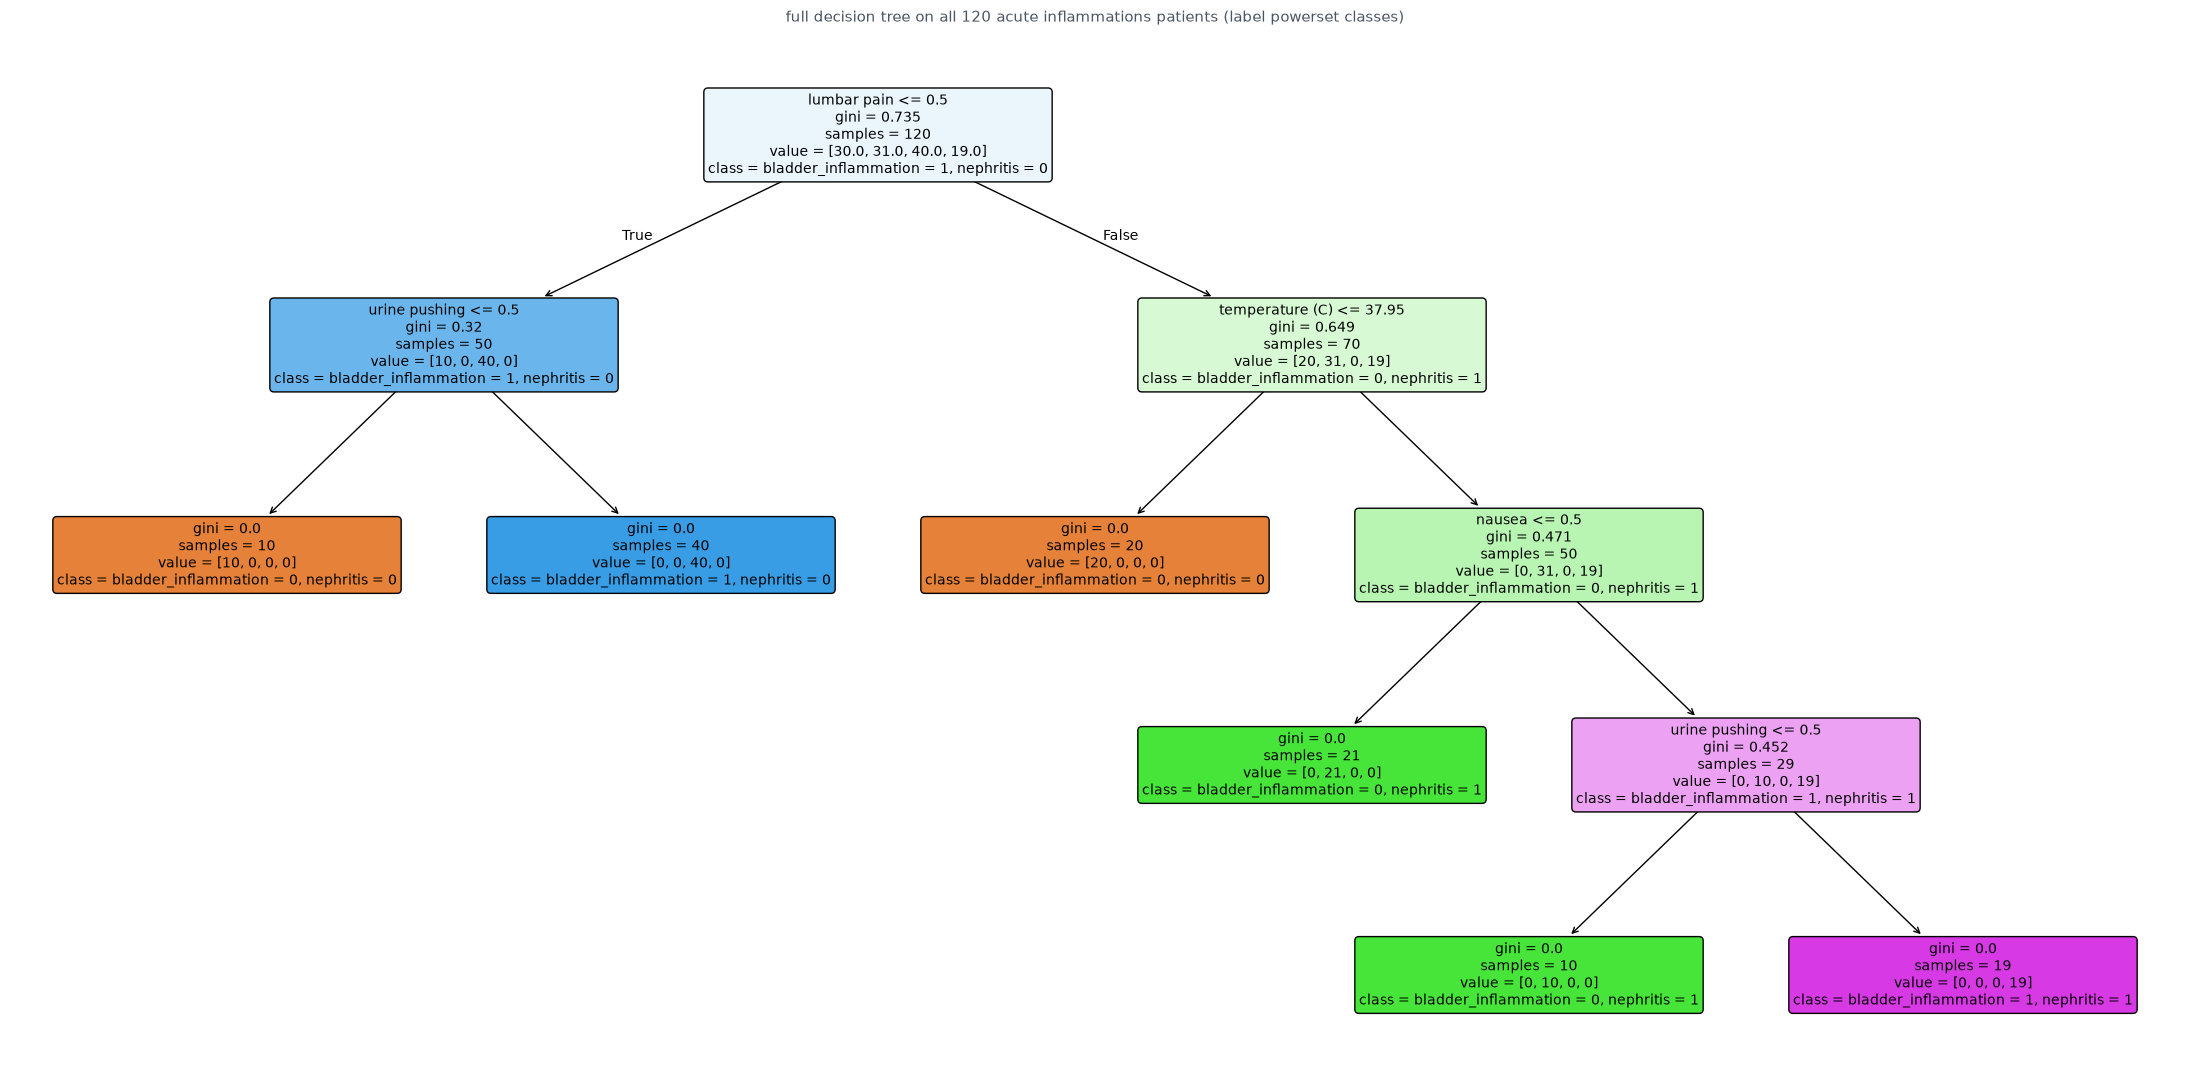

In [3]:
X_acute = acute[PREDICTORS].to_numpy()
y_acute = (acute[INFLAMMATION] * 2 + acute[NEPHRITIS]).to_numpy()  # powerset classes

full_tree = DecisionTreeClassifier(random_state=RNG_SEED)
full_tree.fit(X_acute, y_acute)

train_exact = float((full_tree.predict(X_acute) == y_acute).mean())
assert train_exact == 1.0, "the full tree should classify every training patient exactly"

print(f"training exact-match accuracy: {train_exact:.4f}")
print(f"tree depth: {full_tree.get_depth()}, leaves: {full_tree.get_n_leaves()}")

fig, ax = plt.subplots(figsize=(22, 11))
plot_tree(full_tree, feature_names=FEATURE_NAMES,
          class_names=[class_names[c] for c in sorted(full_tree.classes_)],
          filled=True, rounded=True, fontsize=10, ax=ax)
ax.set_title("full decision tree on all 120 acute inflammations patients "
             "(label powerset classes)", color=NEUTRAL)
plt.tight_layout()
plt.show()


1(b). The tree classifies all 120 patients exactly (training exact-match
accuracy 1.0000) with depth 4 and 6 leaves. It splits on lumbar pain, then
urine pushing and temperature (37.95 C threshold), and nausea in the
high-temperature branch; every leaf is pure.


## 1(c) IF-THEN rules


In [4]:
from sklearn.tree import _tree


def tree_rules(clf, feature_names, class_names, binary_features):
    """render every root-to-leaf path of a fitted tree as an IF-THEN rule.

    `binary_features` are 0/1 columns whose only split point is 0.5, so the
    left branch reads "is 'no'" and the right branch "is 'yes'".
    """
    t = clf.tree_
    rules = []
    def rec(node, conds):
        if t.children_left[node] == _tree.TREE_LEAF:  # leaves have no children (-1)
            rules.append((conds, node))
            return
        name = feature_names[t.feature[node]]
        thr = float(t.threshold[node])
        if name in binary_features:
            assert thr == 0.5, f"{name}: expected the single binary split 0.5, got {thr}"
            cond_l, cond_r = f"{name} is 'no'", f"{name} is 'yes'"
        else:
            cond_l, cond_r = f"{name} <= {thr:.2f}", f"{name} > {thr:.2f}"
        rec(t.children_left[node], conds + [cond_l])
        rec(t.children_right[node], conds + [cond_r])

    rec(0, [])
    out = []
    for i, (conds, leaf) in enumerate(rules, 1):
        cls = int(np.argmax(t.value[leaf][0]))
        lines = [f"RULE {i}"]
        lines += [f"  {'IF' if j == 0 else 'AND'} {c}" for j, c in enumerate(conds)]
        lines.append(f"  THEN prediction: {class_names[cls]}")
        out.append("\n".join(lines))
    return "\n\n".join(out)


print(tree_rules(full_tree, FEATURE_NAMES,
                 [class_names[c] for c in sorted(full_tree.classes_)],
                 binary_features=set(FEATURE_NAMES[1:])))


RULE 1
  IF lumbar pain is 'no'
  AND urine pushing is 'no'
  THEN prediction: bladder_inflammation = 0, nephritis = 0

RULE 2
  IF lumbar pain is 'no'
  AND urine pushing is 'yes'
  THEN prediction: bladder_inflammation = 1, nephritis = 0

RULE 3
  IF lumbar pain is 'yes'
  AND temperature (C) <= 37.95
  THEN prediction: bladder_inflammation = 0, nephritis = 0

RULE 4
  IF lumbar pain is 'yes'
  AND temperature (C) > 37.95
  AND nausea is 'no'
  THEN prediction: bladder_inflammation = 0, nephritis = 1

RULE 5
  IF lumbar pain is 'yes'
  AND temperature (C) > 37.95
  AND nausea is 'yes'
  AND urine pushing is 'no'
  THEN prediction: bladder_inflammation = 0, nephritis = 1

RULE 6
  IF lumbar pain is 'yes'
  AND temperature (C) > 37.95
  AND nausea is 'yes'
  AND urine pushing is 'yes'
  THEN prediction: bladder_inflammation = 1, nephritis = 1


1(c). The 6 root-to-leaf rules above partition all 120 patients into pure
leaves; e.g. IF lumbar pain is 'yes' AND temperature > 37.95 AND nausea is
'no' THEN bladder_inflammation = 0, nephritis = 1.


## 1(d) cost-complexity pruning


,ccp_alpha,cv_mean_accuracy,cv_std_accuracy,train_accuracy,depth,leaves
0,0,0.991667,0.0166667,1,4,6
1,0.0981667,0.858333,0.05,0.841667,2,4
2,0.133333,0.758333,0.0666667,0.758333,2,3
3,0.182,0.666667,0.0589256,0.591667,1,2
4,0.222917,0.483333,0.122474,0.333333,0,1


best mean CV accuracy 0.9917 (std 0.0167, one SE = 0.0075, threshold = 0.9842)
trees within one SE: [0.0]
selected ccp_alpha = 0.0000


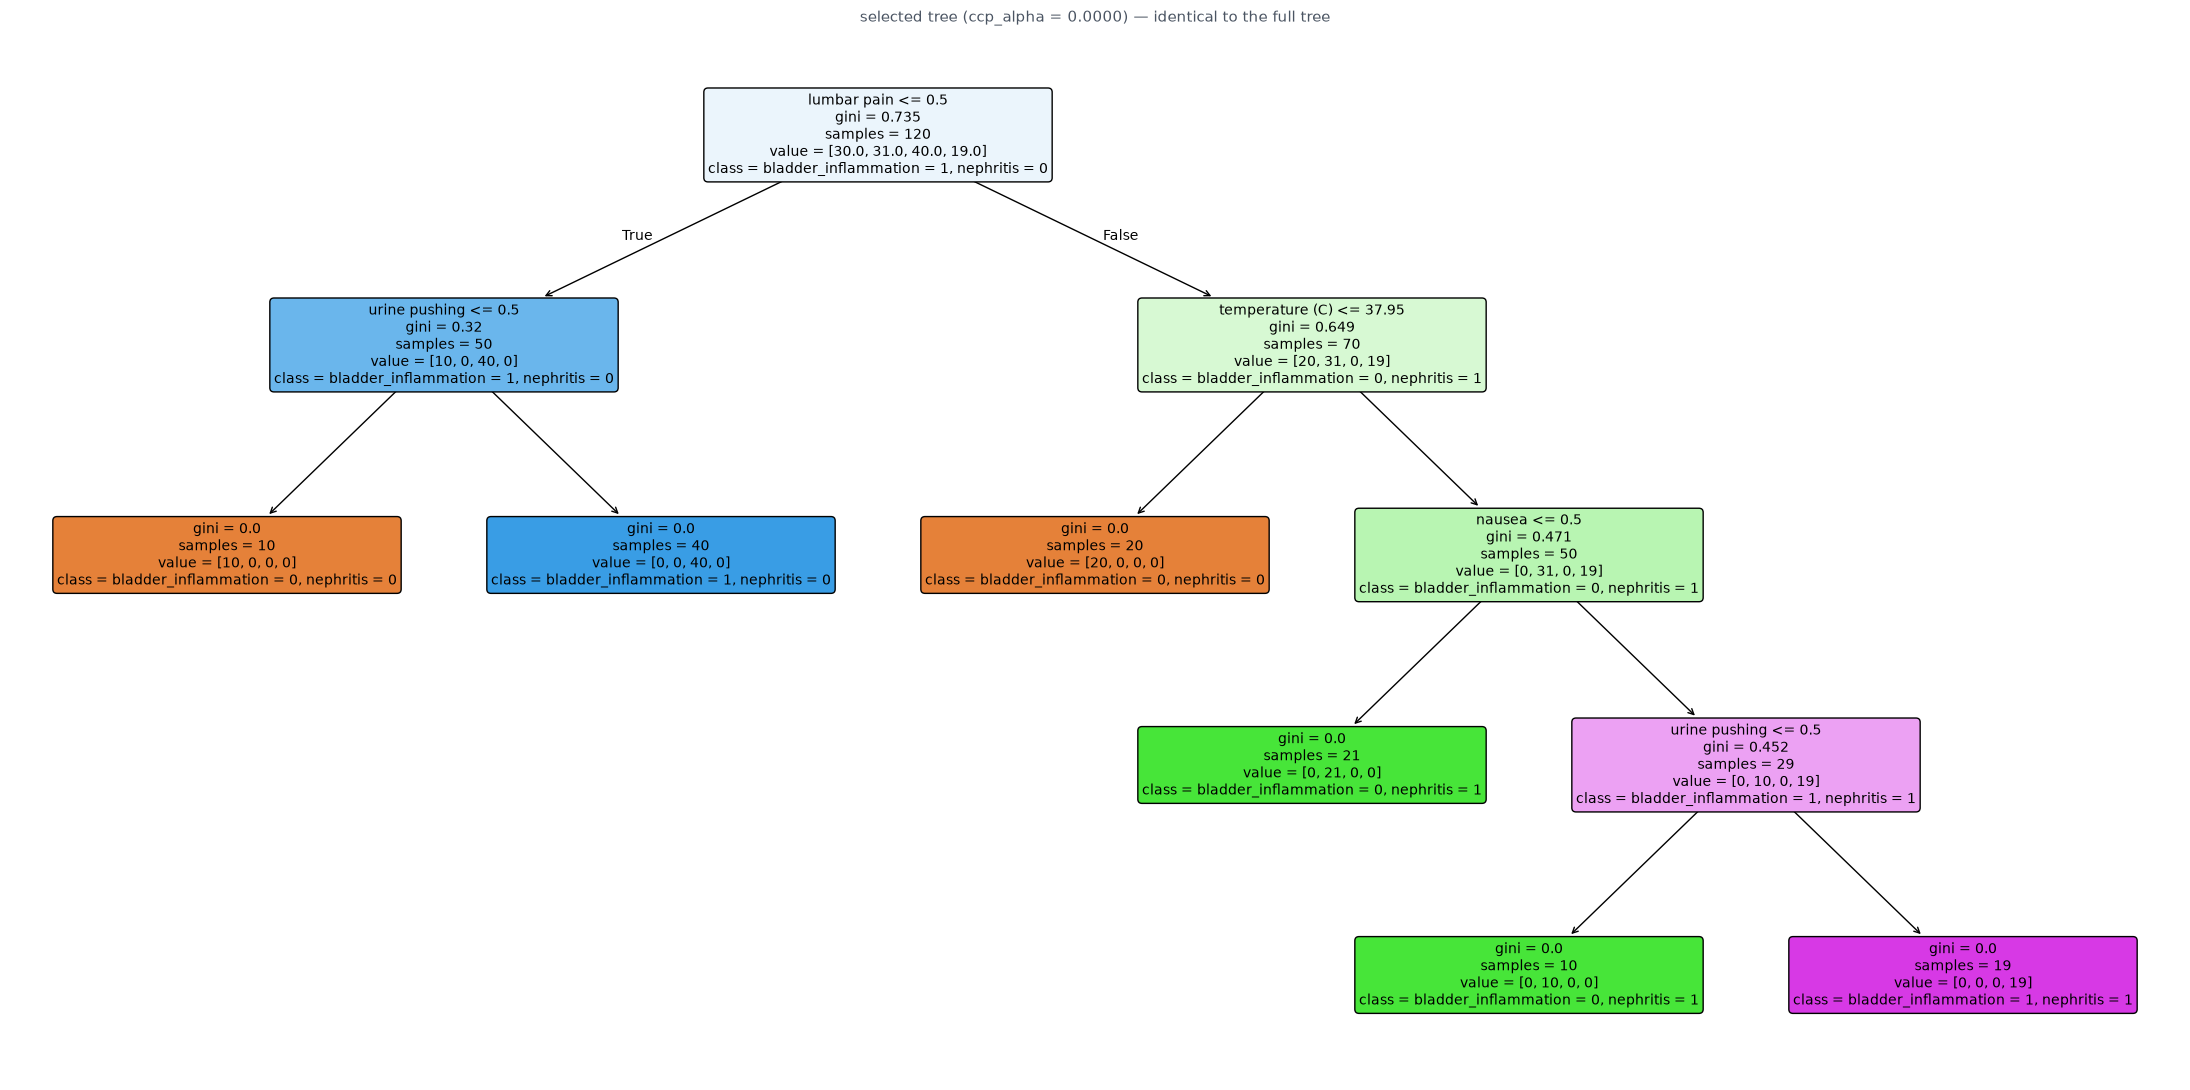


IF-THEN rules of the selected (pruned) tree:
RULE 1
  IF lumbar pain is 'no'
  AND urine pushing is 'no'
  THEN prediction: bladder_inflammation = 0, nephritis = 0

RULE 2
  IF lumbar pain is 'no'
  AND urine pushing is 'yes'
  THEN prediction: bladder_inflammation = 1, nephritis = 0

RULE 3
  IF lumbar pain is 'yes'
  AND temperature (C) <= 37.95
  THEN prediction: bladder_inflammation = 0, nephritis = 0

RULE 4
  IF lumbar pain is 'yes'
  AND temperature (C) > 37.95
  AND nausea is 'no'
  THEN prediction: bladder_inflammation = 0, nephritis = 1

RULE 5
  IF lumbar pain is 'yes'
  AND temperature (C) > 37.95
  AND nausea is 'yes'
  AND urine pushing is 'no'
  THEN prediction: bladder_inflammation = 0, nephritis = 1

RULE 6
  IF lumbar pain is 'yes'
  AND temperature (C) > 37.95
  AND nausea is 'yes'
  AND urine pushing is 'yes'
  THEN prediction: bladder_inflammation = 1, nephritis = 1


In [5]:
skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=RNG_SEED)
counts = np.bincount(y_acute)
assert counts.min() >= N_FOLDS, f"smallest powerset class has {counts.min()} < {N_FOLDS} patients"

prune_path = full_tree.cost_complexity_pruning_path(X_acute, y_acute)
prune_rows = []
for a in prune_path.ccp_alphas:
    m = DecisionTreeClassifier(random_state=RNG_SEED, ccp_alpha=float(a))
    scores = cross_val_score(m, X_acute, y_acute, cv=skf, scoring="accuracy")
    m.fit(X_acute, y_acute)
    prune_rows.append({"ccp_alpha": float(a), "cv_mean_accuracy": scores.mean(),
                       "cv_std_accuracy": scores.std(),
                       "train_accuracy": m.score(X_acute, y_acute),
                       "depth": m.get_depth(), "leaves": m.get_n_leaves()})
prune_table = pd.DataFrame(prune_rows)
display(prune_table)

best_mean = prune_table["cv_mean_accuracy"].max()
best_std = float(prune_table.loc[prune_table["cv_mean_accuracy"].idxmax(), "cv_std_accuracy"])
one_se = best_std / np.sqrt(N_FOLDS)          # standard error of the best mean CV accuracy
threshold = best_mean - one_se

# one-standard-error rule: keep the simplest tree whose mean CV accuracy is
# still within one SE of the best; "simplest" = fewest leaves, ties by largest alpha
window = prune_table[prune_table["cv_mean_accuracy"] >= threshold]
selected = window.sort_values(["leaves", "ccp_alpha"], ascending=[True, False]).iloc[0]
selected_alpha = float(selected["ccp_alpha"])

pruned_tree = DecisionTreeClassifier(random_state=RNG_SEED, ccp_alpha=selected_alpha).fit(X_acute, y_acute)

print(f"best mean CV accuracy {best_mean:.4f} (std {best_std:.4f}, "
      f"one SE = {one_se:.4f}, threshold = {threshold:.4f})")
print(f"trees within one SE: {sorted(window['ccp_alpha'].tolist())}")
print(f"selected ccp_alpha = {selected_alpha:.4f}")

fig, ax = plt.subplots(figsize=(22, 11))
plot_tree(pruned_tree, feature_names=FEATURE_NAMES,
          class_names=[class_names[c] for c in sorted(pruned_tree.classes_)],
          filled=True, rounded=True, fontsize=10, ax=ax)
ax.set_title(f"selected tree (ccp_alpha = {selected_alpha:.4f}) — identical to the full tree",
             color=NEUTRAL)
plt.tight_layout()
plt.show()

print("\nIF-THEN rules of the selected (pruned) tree:")
print(tree_rules(pruned_tree, FEATURE_NAMES,
                 [class_names[c] for c in sorted(pruned_tree.classes_)],
                 binary_features=set(FEATURE_NAMES[1:])))


1(d). The pruning path offers five alphas (0, 0.0982, 0.1333, 0.1820,
0.2229) and CV accuracy collapses under any pruning (0.9917 at alpha = 0,
then 0.8583, 0.7583, 0.6667, 0.4833). The one-standard-error rule therefore
selects alpha = 0: the minimal tree is the unpruned one (depth 4, 6 leaves,
training accuracy 1.0000, CV accuracy 0.9917), plotted above with its rules.


## 2(a) the communities and crime data

Data: [UCI Communities and Crime](https://archive.ics.uci.edu/dataset/183/communities+and+crime).


In [6]:
CRIME_DIR = Path("../data")
RESPONSE = "ViolentCrimesPerPop"
NON_PREDICTIVE = ["state", "county", "community", "communityname", "fold"]

attribute_names = re.findall(r"@attribute\s+(\S+)\s+(?:numeric|string)",
                             (CRIME_DIR / "communities.names").read_text())
crime = pd.read_csv(CRIME_DIR / "communities.data", header=None,
                    names=attribute_names, na_values="?")

assert crime.shape == (1994, 128), f"expected 1994 x 128, got {crime.shape}"
assert len(attribute_names) == 128
assert set(NON_PREDICTIVE) <= set(attribute_names) and RESPONSE in attribute_names
predictors = [a for a in attribute_names if a not in NON_PREDICTIVE + [RESPONSE]]
assert len(NON_PREDICTIVE) == 5 and len(predictors) == 122

crime_train = crime.iloc[:1495]          # exact split, no shuffling
crime_test = crime.iloc[1495:]
assert crime_train.shape == (1495, 128) and crime_test.shape == (499, 128)

print(f"total fields: {len(attribute_names)}, non-predictive removed: {NON_PREDICTIVE}")
print(f"predictive features: {len(predictors)}, response: {RESPONSE}")
print(f"train: {crime_train.shape[0]} rows, test: {crime_test.shape[0]} rows")


total fields: 128, non-predictive removed: ['state', 'county', 'community', 'communityname', 'fold']
predictive features: 122, response: ViolentCrimesPerPop
train: 1495 rows, test: 499 rows


2(a). The file loads as 1,994 x 128 with all names parsed from
communities.names; the 5 non-predictive fields are dropped (122 predictors
plus the response) and the unshuffled split is 1,495 train / 499 test rows.


## 2(b) missing values


In [7]:
miss_cnt = crime[predictors].isna().sum()
missing_table = (pd.DataFrame({"missing count": miss_cnt,
                               "missing %": 100 * miss_cnt / len(crime)})
                 .sort_values("missing count", ascending=False))
display(missing_table[missing_table["missing count"] > 0])

# median imputation fitted on the training rows only
imputer = SimpleImputer(strategy="median").fit(crime_train[predictors])
X_train_imp = pd.DataFrame(imputer.transform(crime_train[predictors]), columns=predictors)
X_test_imp = pd.DataFrame(imputer.transform(crime_test[predictors]), columns=predictors)
y_train = crime_train[RESPONSE].to_numpy()
y_test = crime_test[RESPONSE].to_numpy()

# the matrices must be entirely numeric and finite (no missing values left)
assert all(np.issubdtype(t, np.number) for t in X_train_imp.dtypes)
assert np.isfinite(X_train_imp.to_numpy()).all() and np.isfinite(X_test_imp.to_numpy()).all()
assert not X_train_imp.isna().any().any() and not X_test_imp.isna().any().any()
assert X_train_imp.shape == (1495, 122) and X_test_imp.shape == (499, 122)

print(f"predictors with missing values: {int((miss_cnt > 0).sum())} of {len(predictors)}")
print(f"missing values after imputation: train {int(X_train_imp.isna().sum().sum())}, "
      f"test {int(X_test_imp.isna().sum().sum())}")


,missing count,missing %
PolicBudgPerPop,1675,84.002
PctPolicAsian,1675,84.002
LemasSwornFT,1675,84.002
LemasSwFTPerPop,1675,84.002
LemasSwFTFieldOps,1675,84.002
LemasSwFTFieldPerPop,1675,84.002
LemasTotalReq,1675,84.002
LemasTotReqPerPop,1675,84.002
PolicPerPop,1675,84.002
RacialMatchCommPol,1675,84.002


predictors with missing values: 23 of 122
missing values after imputation: train 0, test 0


2(b). 23 predictors have missing values (22 LEMAS features miss 84.00%,
OtherPerCap misses 1 entry); median imputation fitted on the training rows
only fills both splits, leaving 0 missing values in train and test, as
asserted above.


## 2(c) correlation matrix


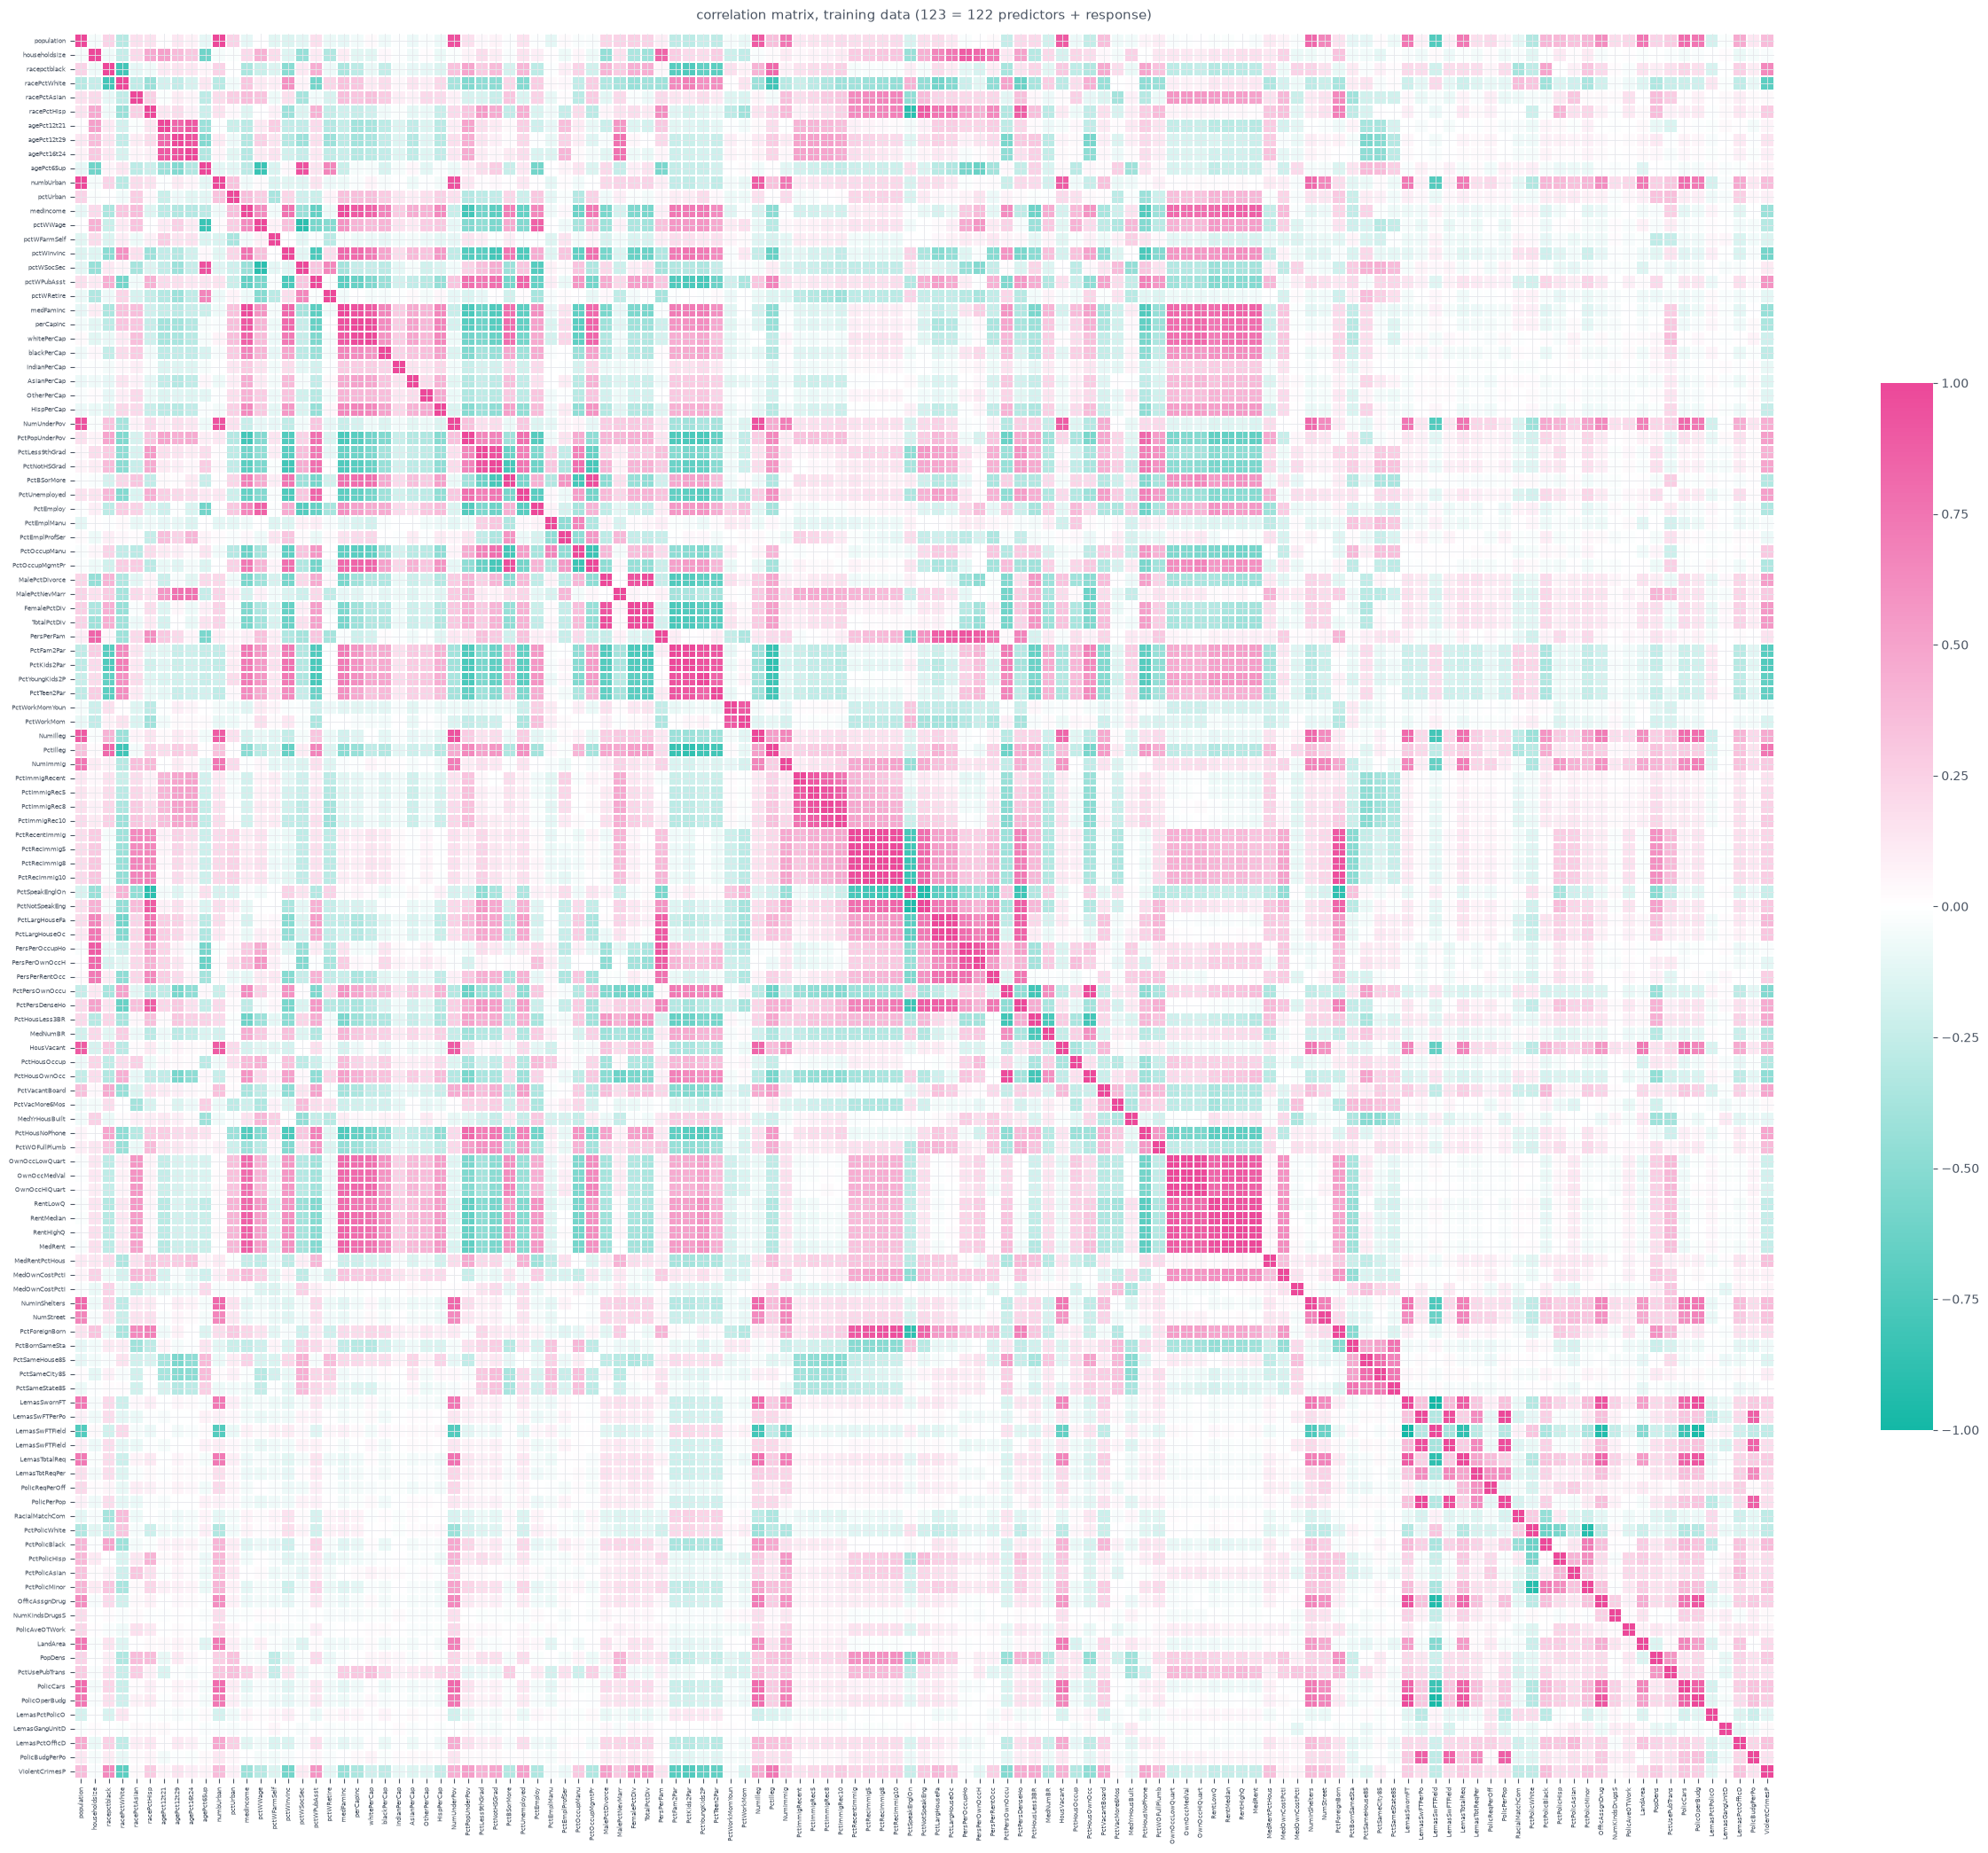

In [8]:
corr = X_train_imp.assign(**{RESPONSE: y_train}).corr()
assert corr.shape == (123, 123) and not corr.isna().any().any()

labels = [c[:14] for c in corr.columns]        # compact labels for the full matrix
fig, ax = plt.subplots(figsize=(25, 21))
sns.heatmap(corr, ax=ax, cmap=CORR_CMAP, vmin=-1, vmax=1, center=0,
            xticklabels=labels, yticklabels=labels,
            cbar_kws={"shrink": 0.6}, linewidths=0.3, linecolor="white")
ax.tick_params(labelsize=5)
ax.set_title("correlation matrix, training data (123 = 122 predictors + response)",
             color=NEUTRAL, pad=12)
plt.tight_layout()
plt.show()


2(c). The matrix shows strong block correlation with several near-duplicate
predictors; the strongest response correlates are PctIlleg (+0.74) and
PctKids2Par (-0.74). This multicollinearity motivates ridge, LASSO and PCR.


## 2(d) coefficients of variation


In [9]:
feat_mean = X_train_imp.mean()
feat_std = X_train_imp.std(ddof=1)          # sample standard deviation
EPS = 1e-12
cv_values = (feat_std / feat_mean).where(feat_mean.abs() > EPS)  # undefined -> NaN, not inf
assert not np.isinf(cv_values).any(), "infinite CVs must be handled, not kept"

n_degenerate = int(feat_mean.abs().le(EPS).sum())
cv_table = (pd.DataFrame({"mean": feat_mean, "std (ddof=1)": feat_std, "CV": cv_values})
            .sort_values("CV", ascending=False))
assert len(cv_table) == 122 and cv_table["CV"].notna().sum() == 122 - n_degenerate
print(f"features with |mean| <= {EPS:g} (CV undefined -> NaN, excluded): {n_degenerate}")
display(cv_table)

features with |mean| <= 1e-12 (CV undefined -> NaN, excluded): 0


,mean,std (ddof=1),CV
PctPolicAsian,0.0162542,0.0898378,5.52706
NumStreet,0.0229833,0.0986654,4.29292
NumInShelters,0.0295987,0.102736,3.47095
NumIlleg,0.037204,0.113806,3.05896
NumImmig,0.0305953,0.0895413,2.92664
LemasPctOfficDrugUn,0.0933043,0.238201,2.55295
NumUnderPov,0.0568495,0.133167,2.34244
LemasSwornFT,0.0287492,0.0646293,2.24804
population,0.0581672,0.130359,2.2411
numbUrban,0.0646488,0.131784,2.03846


2(d). The table lists mean, sample standard deviation and CV for all 122
predictors; none has a near-zero mean, so all CVs are finite. The highest-CV
features (PctPolicAsian 5.53, NumStreet 4.29, NumInShelters 3.47) are counts
of rare events, not necessarily good predictors.


## 2(e) the floor(sqrt(128)) = 11 highest-CV features


the 11 highest-CV features: ['PctPolicAsian', 'NumStreet', 'NumInShelters', 'NumIlleg', 'NumImmig', 'LemasPctOfficDrugUn', 'NumUnderPov', 'LemasSwornFT', 'population', 'numbUrban', 'HousVacant']


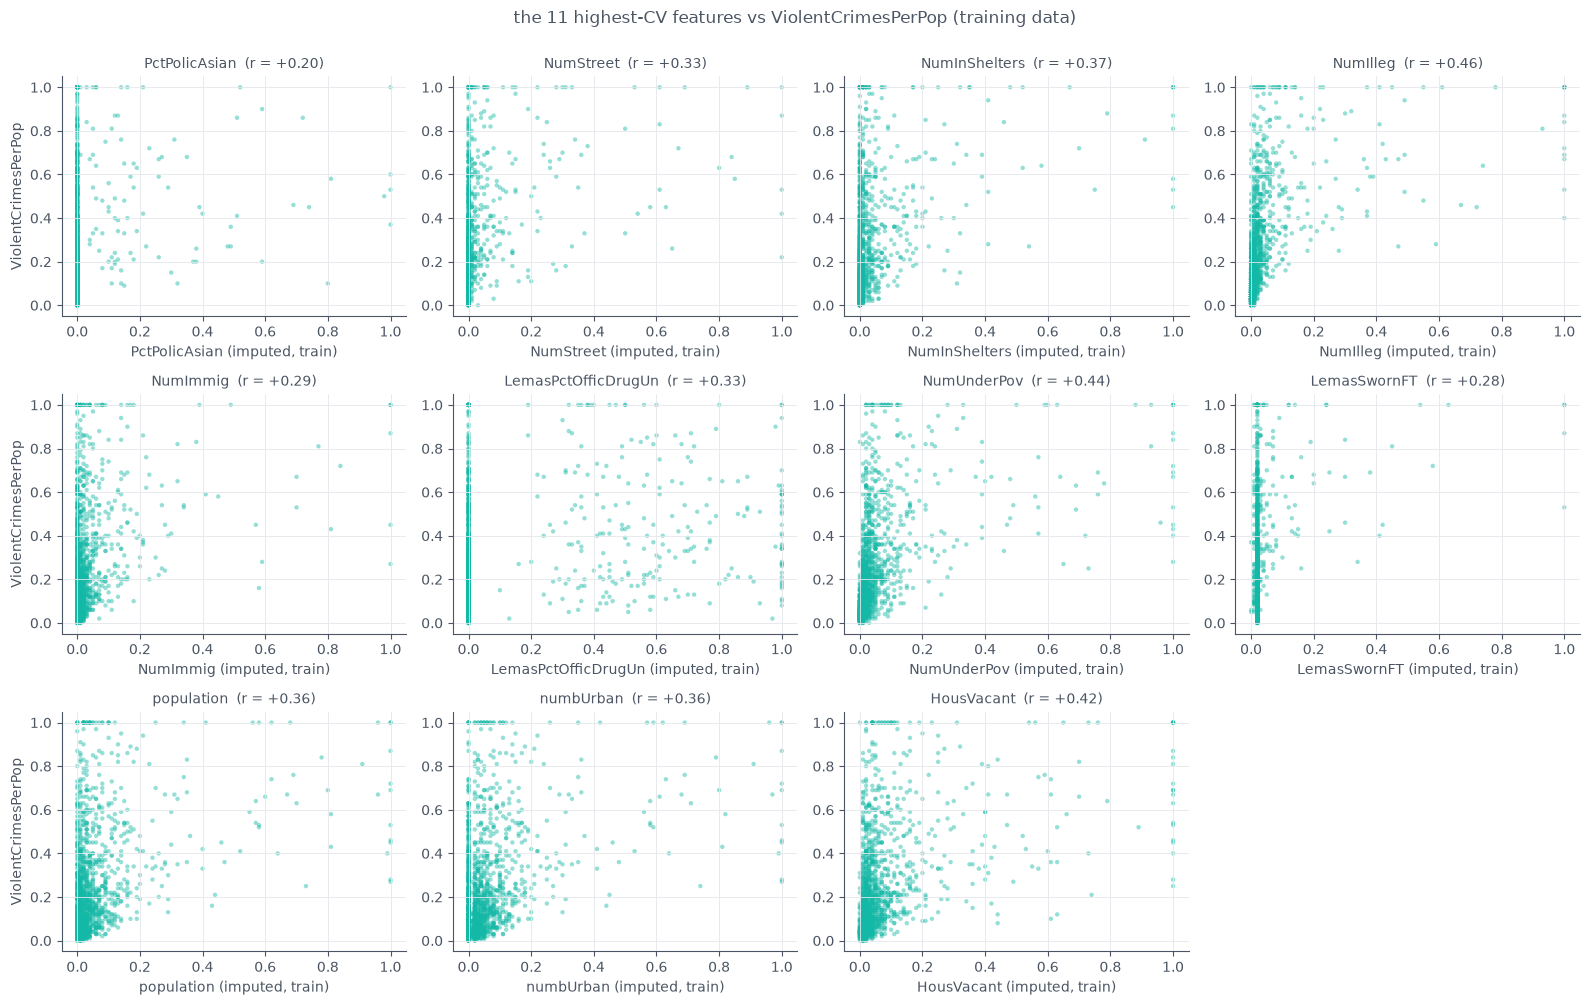

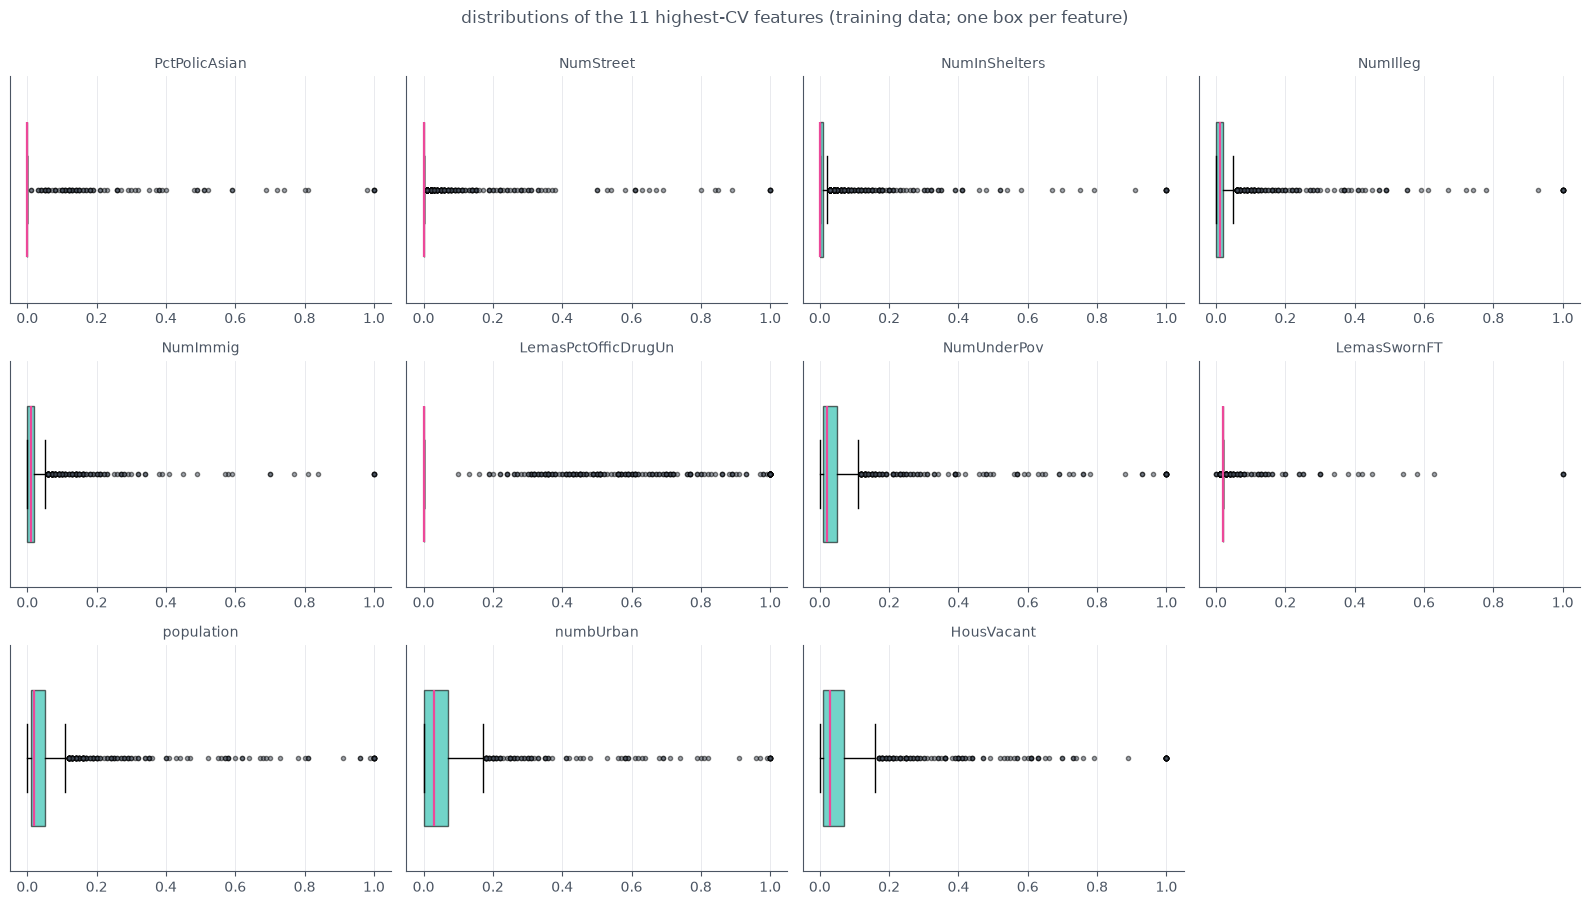

In [10]:
n_pick = math.isqrt(128)                    # floor(sqrt(128)) = 11
assert n_pick == 11
top_cv = cv_table.dropna(subset=["CV"]).head(n_pick)
high_cv_features = list(top_cv.index)
assert high_cv_features == ["PctPolicAsian", "NumStreet", "NumInShelters", "NumIlleg",
                            "NumImmig", "LemasPctOfficDrugUn", "NumUnderPov",
                            "LemasSwornFT", "population", "numbUrban", "HousVacant"]
print(f"the {n_pick} highest-CV features: {high_cv_features}")

fig, axes = plt.subplots(3, 4, figsize=(16, 10))
for k, (ax, feat) in enumerate(zip(axes.ravel(), high_cv_features)):
    ax.scatter(X_train_imp[feat], y_train, s=10, color=TEAL, alpha=0.45, edgecolors="none")
    r = float(np.corrcoef(X_train_imp[feat], y_train)[0, 1])
    ax.set_title(f"{feat}  (r = {r:+.2f})", fontsize=10)
    ax.set_xlabel(f"{feat} (imputed, train)")
    if k % 4 == 0:
        ax.set_ylabel(RESPONSE)
axes.ravel()[-1].axis("off")
plt.suptitle("the 11 highest-CV features vs ViolentCrimesPerPop (training data)",
             color=NEUTRAL, y=1.0)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(3, 4, figsize=(16, 9))
for k, (ax, feat) in enumerate(zip(axes.ravel(), high_cv_features)):
    ax.boxplot(X_train_imp[feat], orientation="horizontal", widths=0.6, patch_artist=True,
               boxprops={"facecolor": TEAL, "alpha": 0.6},
               medianprops={"color": PINK, "linewidth": 1.6},
               flierprops={"marker": "o", "markersize": 3,
                           "markerfacecolor": NEUTRAL, "alpha": 0.5})
    ax.set_title(f"{feat}", fontsize=10)
    ax.set_yticks([])
axes.ravel()[-1].axis("off")
plt.suptitle("distributions of the 11 highest-CV features (training data; one box per feature)",
             color=NEUTRAL, y=1.0)
plt.tight_layout()
plt.show()


2(e). The scatterplots show positive, heteroscedastic trends (r in each
title) and the boxplots show strong right skew and outliers - which is what
inflates the CVs. No, significance cannot be judged from scatter plots alone:
they carry no measure of uncertainty and no control for the other predictors.


## 2(f) ordinary least squares


In [11]:
ols = LinearRegression().fit(X_train_imp, y_train)
pred_tr, pred_te = ols.predict(X_train_imp), ols.predict(X_test_imp)

ols_train_mse = mean_squared_error(y_train, pred_tr)
ols_test_mse = mean_squared_error(y_test, pred_te)
kf = KFold(n_splits=N_FOLDS, shuffle=True, random_state=RNG_SEED)
# CV estimate: imputation re-fitted inside every fold through a pipeline, so no
# validation fold is ever filled with another fold's medians (matches 2(g)-2(j))
ols_cv_pipe = Pipeline([("impute", SimpleImputer(strategy="median")),
                        ("ols", LinearRegression())])
ols_cv_mse = float(-cross_val_score(ols_cv_pipe, crime_train[predictors], y_train,
                                    cv=kf, scoring="neg_mean_squared_error").mean())
assert X_train_imp.shape[1] == 122

display(pd.DataFrame(
    {"OLS": {"train MSE": ols_train_mse, "test MSE": ols_test_mse,
             "5-fold CV MSE (train)": ols_cv_mse}}))


,OLS
train MSE,0.0162924
test MSE,0.0179662
5-fold CV MSE (train),0.0208008


2(f). Test MSE 0.01797 (training MSE 0.01629, CV MSE 0.02080). OLS is
unregularized and high-variance under the observed multicollinearity: its
coefficients on near-duplicate predictors are unstable, which the penalized
models below address.


## 2(g) ridge regression


In [12]:
ridge_grid = np.logspace(-3, 3, 61)
ridge_pipe = Pipeline([("impute", SimpleImputer(strategy="median")),
                       ("scale", StandardScaler()),
                       ("ridge", Ridge(random_state=RNG_SEED))])

ridge_cv = np.array([-cross_val_score(ridge_pipe.set_params(ridge__alpha=a),
                                      crime_train[predictors], y_train, cv=kf,
                                      scoring="neg_mean_squared_error").mean()
                     for a in ridge_grid])
best_i = int(np.argmin(ridge_cv))
assert 0 < best_i < len(ridge_grid) - 1, "ridge optimum at a grid edge - widen the grid"
ridge_alpha = float(ridge_grid[best_i])

ridge_pipe.set_params(ridge__alpha=ridge_alpha).fit(crime_train[predictors], y_train)
ridge_train_mse = mean_squared_error(y_train, ridge_pipe.predict(crime_train[predictors]))
ridge_test_mse = mean_squared_error(y_test, ridge_pipe.predict(crime_test[predictors]))

print(f"best alpha = {ridge_alpha:.4g}, CV MSE = {ridge_cv[best_i]:.5f}, "
      f"train MSE = {ridge_train_mse:.5f}, test MSE = {ridge_test_mse:.5f}")


best alpha = 125.9, CV MSE = 0.01974, train MSE = 0.01723, test MSE = 0.01737


2(g). Five-fold CV selects alpha = 125.9 (interior to the 10^-3..10^3 grid)
with test MSE 0.01737 (training 0.01723, CV 0.01974), beating OLS as expected
under collinearity.


## 2(h) LASSO with and without standardization


In [13]:
NZ_TOL = 1e-6     # |coef| <= 1e-6 treated as exactly zero (documented tolerance)

lasso_grid_raw = np.logspace(-6, 0, 49)
lasso_grid_std = np.logspace(-4, 0, 33)


def fit_lasso(grid, standardize):
    pipe = Pipeline([("impute", SimpleImputer(strategy="median"))] +
                    ([("scale", StandardScaler())] if standardize else []) +
                    [("lasso", Lasso(max_iter=100_000, random_state=RNG_SEED))])
    cv = np.array([-cross_val_score(pipe.set_params(lasso__alpha=a),
                                    crime_train[predictors], y_train, cv=kf,
                                    scoring="neg_mean_squared_error").mean()
                   for a in grid])
    i = int(np.argmin(cv))
    assert 0 < i < len(grid) - 1, "lasso optimum at a grid edge - widen the grid"
    pipe.set_params(lasso__alpha=grid[i]).fit(crime_train[predictors], y_train)
    coef = pipe.named_steps["lasso"].coef_
    assert len(coef) == 122
    return {"pipe": pipe, "grid": grid, "cv": cv, "best_i": i, "coef": coef}


raw_lasso = fit_lasso(lasso_grid_raw, standardize=False)
std_lasso = fit_lasso(lasso_grid_std, standardize=True)


def lasso_report(tag, res):
    pipe, grid, cv, i, coef = res["pipe"], res["grid"], res["cv"], res["best_i"], res["coef"]
    nz = [(n, c) for n, c in zip(predictors, coef) if abs(c) > NZ_TOL]
    nz.sort(key=lambda t: -abs(t[1]))
    tr = mean_squared_error(y_train, pipe.predict(crime_train[predictors]))
    te = mean_squared_error(y_test, pipe.predict(crime_test[predictors]))
    print(f"--- {tag}: best alpha = {grid[i]:.4g}, CV MSE = {cv[i]:.5f}, "
          f"train MSE = {tr:.5f}, test MSE = {te:.5f}, nonzero coefs = {len(nz)}")
    return pd.DataFrame(nz, columns=["variable", "coefficient"]).assign(rank=lambda d: range(1, len(d) + 1))


raw_table = lasso_report("LASSO on source-normalized features (no extra scaling)", raw_lasso)
std_table = lasso_report("LASSO on standardized features", std_lasso)
print(f"\nselected-variable overlap between the two models: "
      f"{len(set(raw_table['variable']) & set(std_table['variable']))} shared")

display(raw_table.style.hide(axis="index").format({"coefficient": "{:+.5f}"}))
display(std_table.style.hide(axis="index").format({"coefficient": "{:+.5f}"}))


--- LASSO on source-normalized features (no extra scaling): best alpha = 0.0001334, CV MSE = 0.01952, train MSE = 0.01706, test MSE = 0.01760, nonzero coefs = 76
--- LASSO on standardized features: best alpha = 0.0005623, CV MSE = 0.01967, train MSE = 0.01684, test MSE = 0.01775, nonzero coefs = 75

selected-variable overlap between the two models: 72 shared


variable,coefficient,rank
racepctblack,+0.26664,1
agePct12t29,-0.23289,2
PctPersDenseHous,+0.20395,3
PctKids2Par,-0.19807,4
NumStreet,+0.15572,5
RentLowQ,-0.15009,6
MedRent,+0.14629,7
PctPopUnderPov,-0.13477,8
PctWorkMom,-0.12548,9
PctEmploy,+0.12119,10


variable,coefficient,rank
racepctblack,+0.06830,1
agePct12t29,-0.04605,2
PctPersDenseHous,+0.04500,3
PctKids2Par,-0.04048,4
MedRent,+0.03278,5
RentLowQ,-0.03249,6
PctPopUnderPov,-0.03091,7
PctEmploy,+0.02706,8
MalePctNevMarr,+0.02701,9
PctIlleg,+0.02341,10


2(h). Source-normalized features: alpha = 1.33e-4, test MSE 0.01760, 76 of
122 variables kept (list above). Standardized: alpha = 5.62e-4, test MSE
0.01775, 75 variables, 72 shared. They are similar because the features are
already normalized to [0, 1], but not identical, since [0, 1] scaling
preserves relative variances while standardizing equalizes them; both beat
OLS.


## 2(i) principal component regression


best M = 60 of 122 components, CV MSE = 0.02021, train MSE = 0.01794, test MSE = 0.01835, cumulative explained variance at M = 98.06%


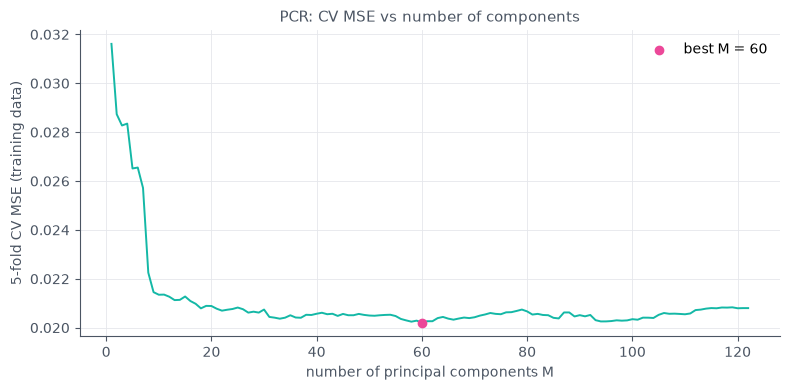

In [14]:
fold_splits = list(kf.split(crime_train[predictors]))
pcr_cv_mse = np.zeros(len(predictors))
for tr_idx, va_idx in fold_splits:
    pre = Pipeline([("impute", SimpleImputer(strategy="median")),
                    ("scale", StandardScaler()), ("pca", PCA())])
    Z_tr = pre.fit_transform(crime_train[predictors].iloc[tr_idx])   # fold-training rows only
    Z_va = pre.transform(crime_train[predictors].iloc[va_idx])
    for M in range(1, len(predictors) + 1):
        lr = LinearRegression().fit(Z_tr[:, :M], y_train[tr_idx])
        pcr_cv_mse[M - 1] += mean_squared_error(y_train[va_idx], lr.predict(Z_va[:, :M]))
pcr_cv_mse /= len(fold_splits)

best_M = int(np.argmin(pcr_cv_mse)) + 1

pcr_pipe = Pipeline([("impute", SimpleImputer(strategy="median")),
                     ("scale", StandardScaler()),
                     ("pca", PCA(n_components=best_M)),
                     ("linreg", LinearRegression())]).fit(crime_train[predictors], y_train)
pcr_train_mse = mean_squared_error(y_train, pcr_pipe.predict(crime_train[predictors]))
pcr_test_mse = mean_squared_error(y_test, pcr_pipe.predict(crime_test[predictors]))

# cumulative explained variance at the selected M (PCA refit on all training rows)
pre_full = Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())])
X_full_pre = pre_full.fit_transform(crime_train[predictors])
cum_var = float(PCA(n_components=best_M).fit(X_full_pre).explained_variance_ratio_.cumsum()[-1])

print(f"best M = {best_M} of 122 components, CV MSE = {pcr_cv_mse[best_M - 1]:.5f}, "
      f"train MSE = {pcr_train_mse:.5f}, test MSE = {pcr_test_mse:.5f}, "
      f"cumulative explained variance at M = {100 * cum_var:.2f}%")

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(np.arange(1, 123), pcr_cv_mse, color=TEAL, lw=1.4)
ax.scatter([best_M], [pcr_cv_mse[best_M - 1]], color=PINK, zorder=3, label=f"best M = {best_M}")
ax.set_xlabel("number of principal components M"), ax.set_ylabel("5-fold CV MSE (training data)")
ax.set_title("PCR: CV MSE vs number of components", color=NEUTRAL)
ax.legend()
plt.tight_layout()
plt.show()


2(i). CV selects M = 60 (test MSE 0.01835, training 0.01794; those
components explain 98.06% of the predictors' variance). PCR is weakest here:
PCA compresses predictors without looking at the response, and variance is a
poor proxy for relevance.


## 2(j) XGBoost with L1 regularization


best reg_alpha = 1, CV MSE = 0.01975, train MSE = 0.00553, test MSE = 0.01553


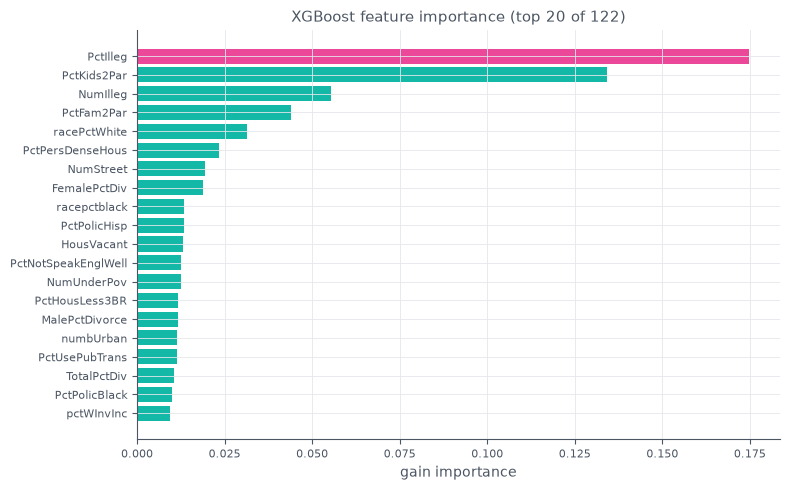

In [15]:
xgb_params = dict(objective="reg:squarederror", n_estimators=500, learning_rate=0.05,
                  max_depth=3, min_child_weight=1, subsample=0.8, colsample_bytree=0.8,
                  reg_lambda=1.0, tree_method="hist", random_state=RNG_SEED,
                  n_jobs=4, importance_type="gain")
reg_alpha_grid = [0.0] + list(np.logspace(-3, 2, 11))
xgb_pipe = Pipeline([("impute", SimpleImputer(strategy="median")),
                     ("xgb", XGBRegressor(**xgb_params))])

xgb_cv = np.array([-cross_val_score(xgb_pipe.set_params(xgb__reg_alpha=a),
                                    crime_train[predictors], y_train, cv=kf,
                                    scoring="neg_mean_squared_error")
                   .mean() for a in reg_alpha_grid])
xgb_best_i = int(np.argmin(xgb_cv))
assert 0 < xgb_best_i < len(reg_alpha_grid) - 1, "xgb optimum at a grid edge - widen the grid"
best_reg_alpha = float(reg_alpha_grid[xgb_best_i])

xgb_pipe.set_params(xgb__reg_alpha=best_reg_alpha).fit(crime_train[predictors], y_train)
xgb_train_mse = mean_squared_error(y_train, xgb_pipe.predict(crime_train[predictors]))
xgb_test_mse = mean_squared_error(y_test, xgb_pipe.predict(crime_test[predictors]))

print(f"best reg_alpha = {best_reg_alpha:g}, CV MSE = {xgb_cv[xgb_best_i]:.5f}, "
      f"train MSE = {xgb_train_mse:.5f}, test MSE = {xgb_test_mse:.5f}")

fig, ax = plt.subplots(figsize=(8, 5))
importances = (pd.Series(xgb_pipe.named_steps["xgb"].feature_importances_, index=predictors)
               .sort_values(ascending=True).tail(20))
ax.barh(importances.index, importances.values, color=TEAL)
ax.barh(importances.index[-1], importances.values[-1], color=PINK)
ax.set_xlabel("gain importance")
ax.set_title("XGBoost feature importance (top 20 of 122)", color=NEUTRAL)
ax.tick_params(labelsize=8)
plt.tight_layout()
plt.show()


2(j). CV selects reg_alpha = 1 (grid includes 0) with test MSE 0.01553
(training 0.00553, CV 0.01975) - the best test error in this assignment.
Fixed hyperparameters: 500 trees, learning rate 0.05, depth-3 trees,
row/column subsampling 0.8, reg_lambda 1.0, seed 42. Gain importance is led
by PctIlleg, PctKids2Par and NumIlleg, matching 2(c).


## final comparison (not asked)


In [16]:
summary = pd.DataFrame({
    "model": ["OLS", "Ridge", "LASSO (source-normalized)", "LASSO (standardized)",
              "PCR", "XGBoost"],
    "selected hyperparameter(s)": ["none (122 features)",
                                   f"alpha = {ridge_alpha:.4g}",
                                   f"alpha = {raw_lasso['grid'][raw_lasso['best_i']]:.4g}",
                                   f"alpha = {std_lasso['grid'][std_lasso['best_i']]:.4g}",
                                   f"M = {best_M} components",
                                   f"reg_alpha = {best_reg_alpha:g}"],
    "train MSE": [ols_train_mse, ridge_train_mse,
                  mean_squared_error(y_train, raw_lasso["pipe"].predict(crime_train[predictors])),
                  mean_squared_error(y_train, std_lasso["pipe"].predict(crime_train[predictors])),
                  pcr_train_mse, xgb_train_mse],
    "test MSE": [ols_test_mse, ridge_test_mse,
                 mean_squared_error(y_test, raw_lasso["pipe"].predict(crime_test[predictors])),
                 mean_squared_error(y_test, std_lasso["pipe"].predict(crime_test[predictors])),
                 pcr_test_mse, xgb_test_mse],
})
summary = summary.sort_values("test MSE").reset_index(drop=True)
assert len(summary) == 6 and summary["test MSE"].min() == xgb_test_mse
display(summary.style.hide(axis="index").format(
    {"train MSE": "{:.5f}", "test MSE": "{:.5f}"}))
print(f"best model by test MSE: {summary.iloc[0]['model']} "
      f"(test MSE {summary.iloc[0]['test MSE']:.5f})")


model,selected hyperparameter(s),train MSE,test MSE
XGBoost,reg_alpha = 1,0.00553,0.01553
Ridge,alpha = 125.9,0.01723,0.01737
LASSO (source-normalized),alpha = 0.0001334,0.01706,0.01760
LASSO (standardized),alpha = 0.0005623,0.01684,0.01775
OLS,none (122 features),0.01629,0.01797
PCR,M = 60 components,0.01794,0.01835


best model by test MSE: XGBoost (test MSE 0.01553)
